# 问题3：条件生成、风味指纹与受约束迁移

这是结果复查Notebook，不是完整训练流程。完整计算入口为 scripts/run_review.py。

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image
OUT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'q1_metrics.csv').is_file()), None)
if OUT is None:
    ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/run_review.py').is_file()), None)
    if ROOT is None: raise FileNotFoundError('请从项目目录或输出目录启动Notebook')
    OUT=Path(os.environ.get('MATHORCUP_OUTPUT',str(ROOT/'results' if (ROOT/'results').is_dir() else ROOT/'outputs/competition_candidate_v3')))
pd.set_option('display.max_rows',160)
pd.set_option('display.max_columns',25)

## 说明

按训练集风格条件进行近邻谱插值，参数规则固定，不基于测试成绩选取。输出是附件1混合尺度上的统计化合物谱，不是已验证浓度配方或酿造工艺。插值不自动保证汇总指标恒等式。四个缺陷原生字段完全冻结；未知值保持未知；Stale hops仅有模型代理约束，非实测缺陷保证。

In [2]:
v=pd.read_csv(OUT/'q3_generation_heldout_validation.csv'); display(v.groupby('mode').mean(numeric_only=True)); display(v); display(pd.read_csv(OUT/'q3_style_diagnostic.csv')); display(pd.read_csv(OUT/'q3_style_sensory_profiles.csv').query("style in ['Tripel','Kriek','Lambic']"))

,n_train,n_test,marginal_wasserstein,mean_shift_RMS,real_nearest_train,generated_nearest_train,duplicate_fraction,outside_training_range,generated_missing_rate,n_generated,variance_features,generated_train_variance_ratio_median,...,generated_total_scaled_variance,holdout_total_scaled_variance,generated_pairwise_RMS_mean,training_pairwise_RMS_mean,generated_to_same_style_train_mean,generated_to_same_style_train_q95,holdout_to_same_style_train_mean,training_leave_one_out_mean,train_nn_radius95,holdout_to_generated_mean,holdout_covered_at_train_nn95,generated_in_train_nn95_fraction
mode,,,,,,,,,,,,,,,,,,,,,,,,,
conditional_local,9.090909,2.272727,0.747896,2.364091,2.457155,0.210414,0.0,0.0,0.001844,100.0,226.045455,0.599933,...,116.654327,185.407979,0.895465,1.225561,0.210414,0.531219,2.615906,0.985407,1.35316,2.540489,0.719697,1.000000
conditional_resample,9.090909,2.272727,0.759844,2.361950,2.457155,0.000000,1.0,0.0,0.001072,100.0,226.045455,0.841429,...,157.981922,185.407979,1.020729,1.225561,0.000000,0.000000,2.615906,0.985407,1.35316,2.615906,0.719697,1.000000
unconditional_local,9.090909,2.272727,0.829752,2.379798,2.457155,0.180643,0.0,0.0,0.002096,100.0,226.045455,3.439848,...,178.020913,185.407979,1.181905,1.225561,1.031451,1.509256,2.615906,0.985407,1.35316,2.460636,0.856061,0.764091


,style,mode,n_train,n_test,marginal_wasserstein,mean_shift_RMS,real_nearest_train,generated_nearest_train,duplicate_fraction,outside_training_range,generated_missing_rate,n_generated,...,holdout_total_scaled_variance,holdout_variance_status,generated_pairwise_RMS_mean,training_pairwise_RMS_mean,generated_to_same_style_train_mean,generated_to_same_style_train_q95,holdout_to_same_style_train_mean,training_leave_one_out_mean,train_nn_radius95,holdout_to_generated_mean,holdout_covered_at_train_nn95,generated_in_train_nn95_fraction
0,Amber,conditional_local,10,2,0.801909,1.132679,1.362666,0.177542,0.0,0.0,0.000779,100,...,465.142184,estimable_but_small_sample,0.876397,1.100258,0.177542,0.447410,1.520926,0.947880,1.021452,1.457948,0.000000,1.00
1,Amber,conditional_resample,10,2,0.813076,1.144398,1.362666,0.000000,1.0,0.0,0.000173,100,...,465.142184,estimable_but_small_sample,0.961875,1.100258,0.000000,0.000000,1.520926,0.947880,1.021452,1.520926,0.000000,1.00
2,Amber,unconditional_local,10,2,0.836219,1.090957,1.362666,0.190396,0.0,0.0,0.002424,100,...,465.142184,estimable_but_small_sample,1.231882,1.100258,0.963318,1.573545,1.520926,0.947880,1.021452,1.361510,0.500000,0.70
3,Blond,conditional_local,25,6,0.407673,0.460315,0.894489,0.197617,0.0,0.0,0.002165,100,...,296.409203,estimable_but_small_sample,1.098119,1.283828,0.197617,0.484818,0.979923,0.886795,1.502068,0.931083,0.833333,1.00
4,Blond,conditional_resample,25,6,0.412740,0.469711,0.894489,0.000000,1.0,0.0,0.001558,100,...,296.409203,estimable_but_small_sample,1.250111,1.283828,0.000000,0.000000,0.979923,0.886795,1.502068,0.979923,0.833333,1.00
5,Blond,unconditional_local,25,6,0.416147,0.474515,0.894489,0.194343,0.0,0.0,0.001861,100,...,296.409203,estimable_but_small_sample,1.100172,1.283828,0.743193,1.214531,0.979923,0.886795,1.502068,0.934220,0.833333,0.99
6,Brett/cofermented,conditional_local,5,1,0.815384,0.978186,0.781249,0.251783,0.0,0.0,0.000000,100,...,NaN,undefined_n_less_than_2,1.166631,1.545564,0.251783,0.600016,0.798320,1.163640,2.023243,0.693449,1.000000,1.00
7,Brett/cofermented,conditional_resample,5,1,0.764009,0.861587,0.781249,0.000000,1.0,0.0,0.000000,100,...,NaN,undefined_n_less_than_2,1.225887,1.545564,0.000000,0.000000,0.798320,1.163640,2.023243,0.798320,1.000000,1.00
8,Brett/cofermented,unconditional_local,5,1,0.702412,0.711680,0.781249,0.173222,0.0,0.0,0.002121,100,...,NaN,undefined_n_less_than_2,1.179327,1.545564,1.030227,1.386851,0.798320,1.163640,2.023243,0.726915,1.000000,0.99
9,Brown,conditional_local,10,2,0.553102,0.683906,0.835087,0.165872,0.0,0.0,0.000693,100,...,242.012720,estimable_but_small_sample,0.821479,1.042415,0.165872,0.427818,1.000828,0.906235,0.997944,0.949909,0.500000,1.00


,heldout_style_accuracy,heldout_balanced_accuracy,generated_condition_agreement
0,0.6,0.55303,0.989545


,style,target,predicted_mean,predicted_q05,predicted_q95,observed_training_mean
550,Kriek,A_malt_all,-0.465037,-0.930286,-0.106708,-0.502183
551,Kriek,A_malt_grain,-0.194920,-0.357739,0.055058,-0.263301
552,Kriek,A_malt_bread,-0.121538,-0.338995,0.126201,-0.206825
553,Kriek,A_malt_cara,-0.352140,-0.704348,-0.068603,-0.383038
554,Kriek,A_malt_burn,-0.205978,-0.259842,-0.102439,-0.204462
555,Kriek,A_hops_all,-0.589449,-0.857373,-0.233051,-0.860889
556,Kriek,A_hops_citrus,-0.292375,-0.343997,-0.219235,-0.437701
557,Kriek,A_hops_tropical,-0.233367,-0.300489,-0.146938,-0.337200
558,Kriek,A_hops_noble,-0.403753,-0.683480,0.023846,-0.616711
559,Kriek,A_hops_woody,-0.071432,-0.184052,0.008037,-0.131238


,source_beer,source_split,target_style,target_donor_beer,alpha,source_target_distance,transferred_target_distance,distance_improvement,relative_distance_improvement,movement,source_stale_predicted,transferred_stale_predicted,source_stale_auxiliary_guard,transferred_stale_auxiliary_guard,defect_native_exactly_preserved,source_trip_probability,transferred_trip_probability,status,before_diagnostic_style,after_diagnostic_style,diagnostic_claim
0,28,heldout_test,Tripel,199,0.75,0.840242,0.212406,0.627836,0.747209,0.629709,-0.055073,-0.055073,0.190278,0.037354,True,0.071872,0.165036,feasible_improvement,Saison,Tripel,"training-fitted classifier only, not independe..."
1,81,training,Tripel,147,0.75,0.992219,0.268501,0.723718,0.729393,0.789474,-0.055073,-0.055073,0.545536,0.132281,True,0.037225,0.122719,feasible_improvement,Pils/Lager,Tripel,"training-fitted classifier only, not independe..."
2,90,training,Tripel,217,0.75,0.918034,0.273204,0.644830,0.702403,0.678910,-0.055073,-0.055073,-0.083476,-0.092353,True,0.025948,0.129976,feasible_improvement,Pils/Lager,Blond,"training-fitted classifier only, not independe..."
3,96,training,Tripel,15,0.75,1.122721,0.294962,0.827759,0.737280,0.839642,-0.055073,-0.055073,0.110083,-0.178806,True,0.022889,0.103399,feasible_improvement,Pils/Lager,Blond,"training-fitted classifier only, not independe..."
4,119,heldout_test,Tripel,85,0.75,0.870876,0.271271,0.599606,0.688508,0.641017,-0.055073,-0.055073,0.033920,-0.177765,True,0.041519,0.118087,feasible_improvement,Pils/Lager,Blond,"training-fitted classifier only, not independe..."
5,124,training,Tripel,239,0.75,1.064395,0.278764,0.785631,0.738101,0.819147,-0.055073,-0.055073,-0.077900,-0.193487,True,0.011311,0.107443,feasible_improvement,Pils/Lager,Blond,"training-fitted classifier only, not independe..."
6,139,training,Tripel,217,0.75,0.988910,0.257524,0.731386,0.739588,0.739607,-0.055073,-0.055073,-0.091661,-0.145425,True,0.024680,0.120215,feasible_improvement,Pils/Lager,Blond,"training-fitted classifier only, not independe..."
7,185,training,Tripel,239,0.75,1.112001,0.301539,0.810462,0.728832,0.829125,-0.055073,-0.055073,-0.020900,-0.204171,True,0.025093,0.117253,feasible_improvement,Pils/Lager,Blond,"training-fitted classifier only, not independe..."
8,209,training,Tripel,239,0.75,1.038366,0.265508,0.772858,0.744302,0.777626,-0.055073,-0.055073,-0.094103,-0.198420,True,0.020040,0.119769,feasible_improvement,Pils/Lager,Blond,"training-fitted classifier only, not independe..."
9,218,training,Tripel,217,0.75,0.862671,0.221206,0.641465,0.743580,0.645932,-0.055073,-0.055073,0.208333,-0.068441,True,0.022718,0.135594,feasible_improvement,Pils/Lager,Tripel,"training-fitted classifier only, not independe..."


,source_beer,field,before_native,after_native,known,guarantee
0,28,DMS,1.437078,1.437078,True,native value unchanged; concentration non-wors...
1,28,X2.3.butanedione,NaN,NaN,False,"unknown retained, no safety claim"
2,28,X4VG,-2.013157,-2.013157,True,native value unchanged; concentration non-wors...
3,28,X.E..2.nonenal,0.011530,0.011530,True,native value unchanged; concentration non-wors...
4,81,DMS,0.947369,0.947369,True,native value unchanged; concentration non-wors...
5,81,X2.3.butanedione,0.284814,0.284814,True,native value unchanged; concentration non-wors...
6,81,X4VG,-2.013157,-2.013157,True,native value unchanged; concentration non-wors...
7,81,X.E..2.nonenal,0.003422,0.003422,True,native value unchanged; concentration non-wors...
8,90,DMS,0.899444,0.899444,True,native value unchanged; concentration non-wors...
9,90,X2.3.butanedione,0.236137,0.236137,True,native value unchanged; concentration non-wors...


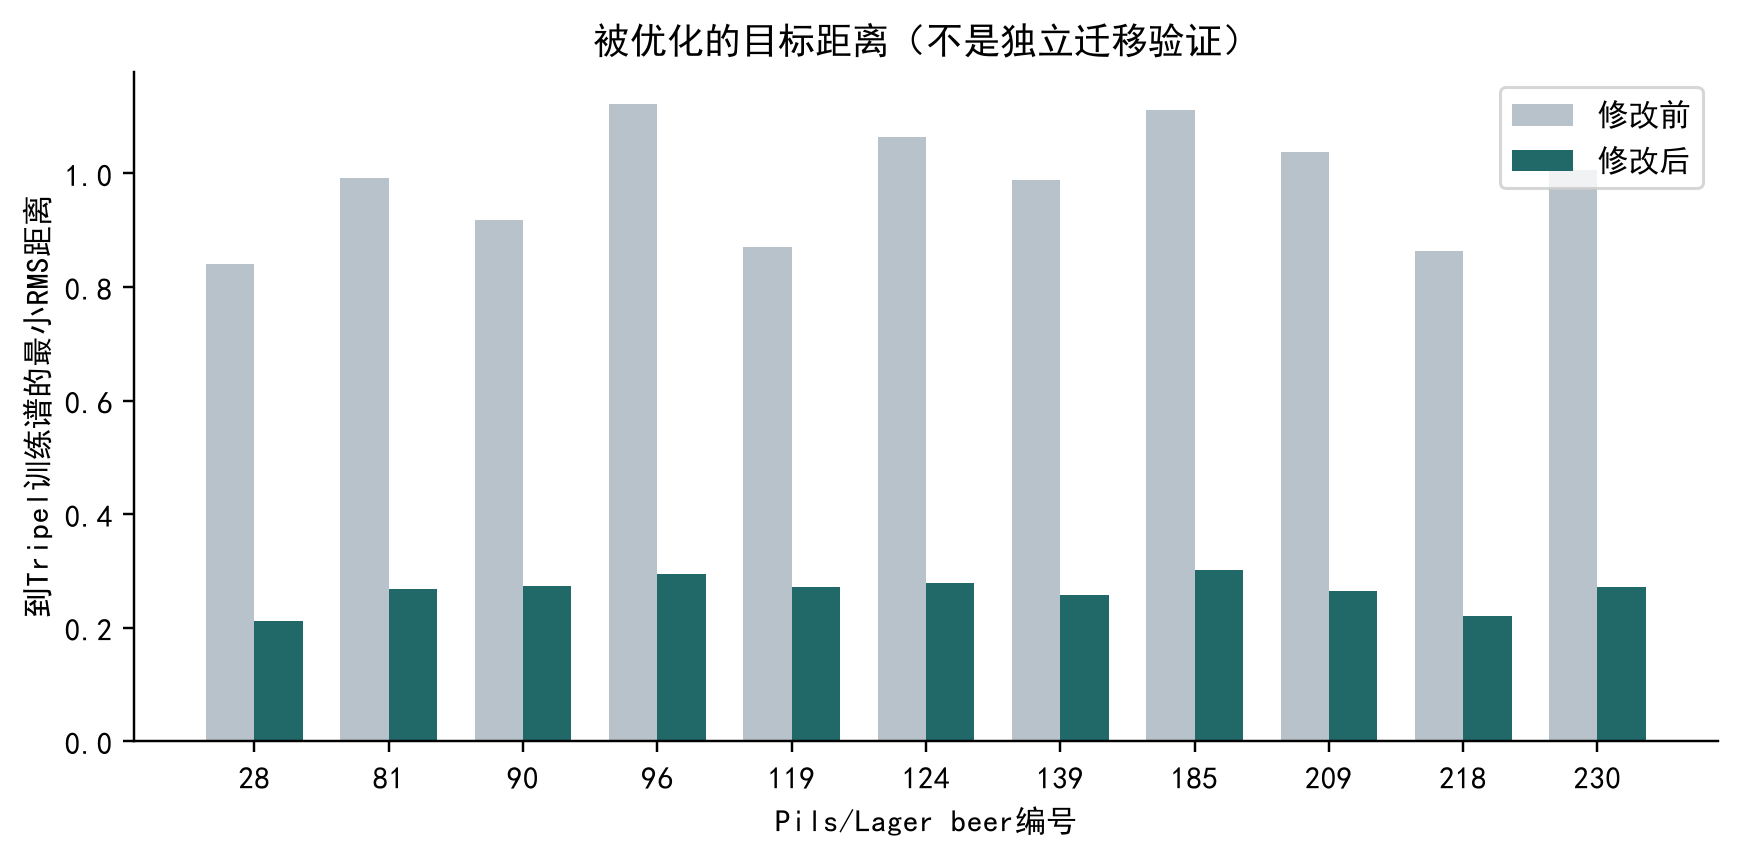

In [3]:
t=pd.read_csv(OUT/'q3_transfer_summary.csv'); display(t); assert t.defect_native_exactly_preserved.all(); assert (t.transferred_stale_auxiliary_guard<=t.source_stale_auxiliary_guard+1e-12).all(); display(pd.read_csv(OUT/'q3_transfer_defect_constraints.csv')); display(Image(filename=str(OUT/'figures/06_transfer.png')))

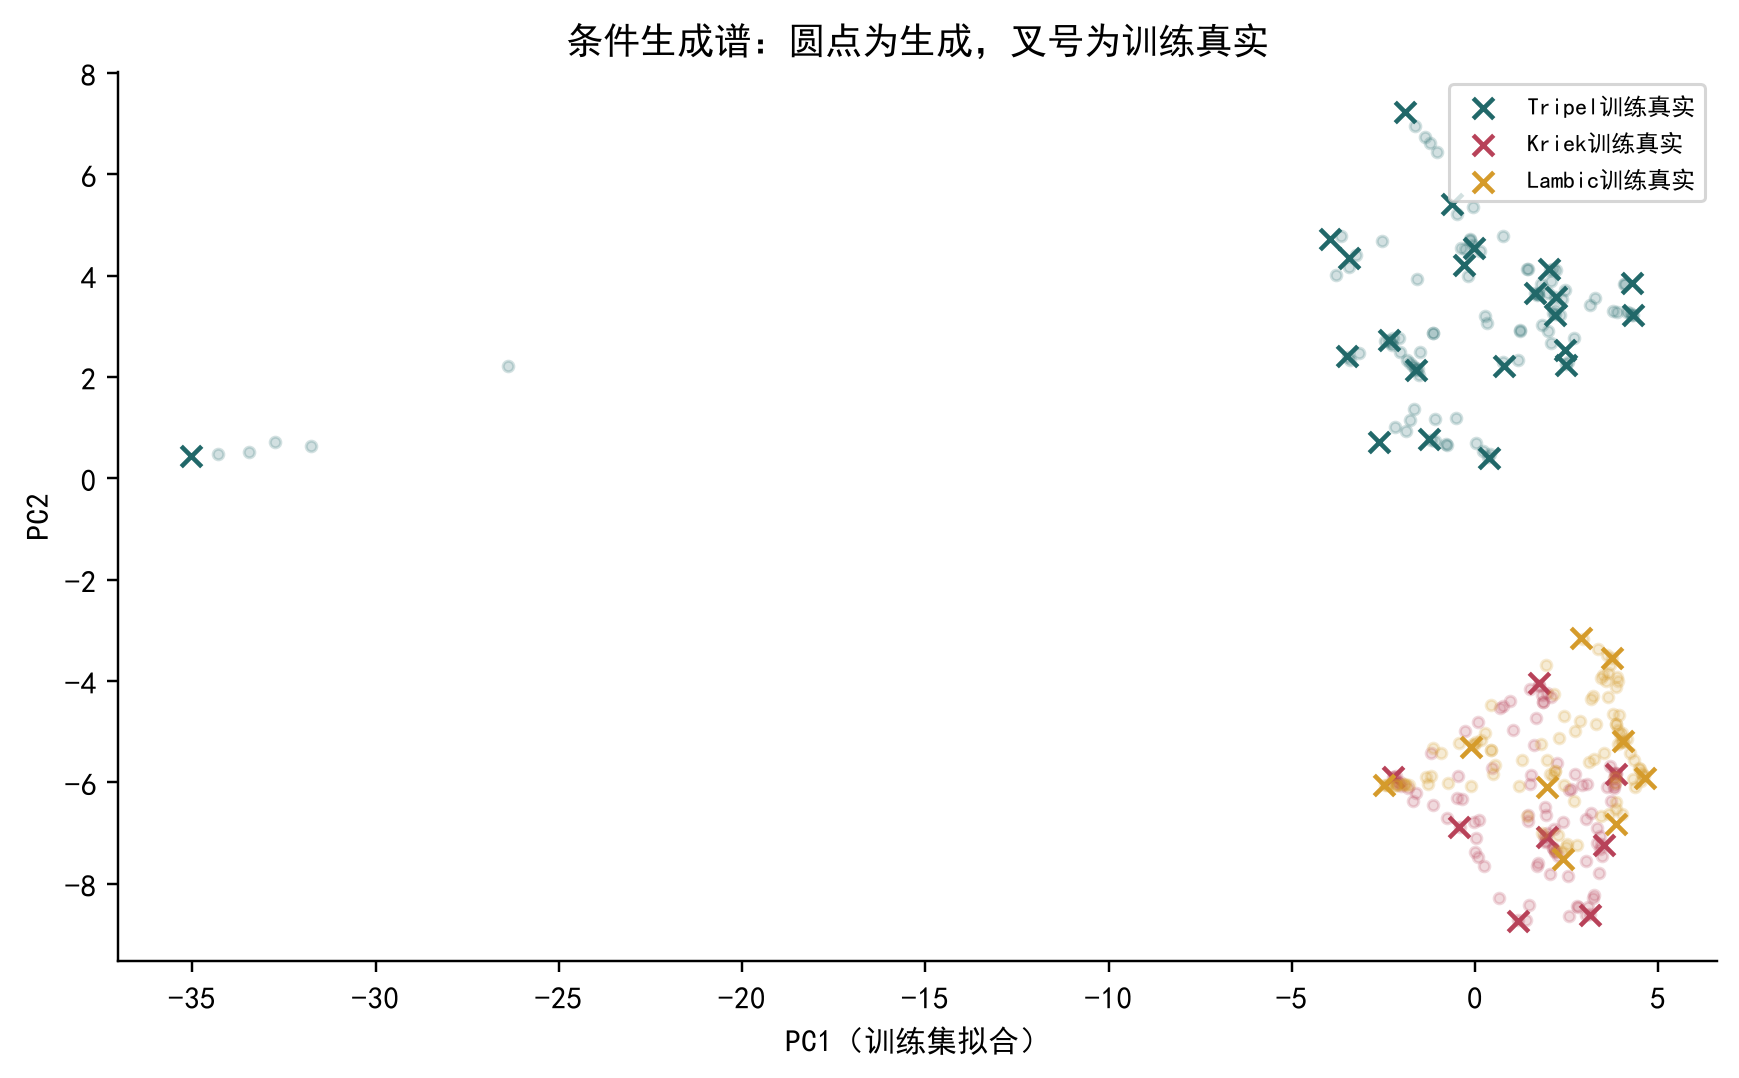

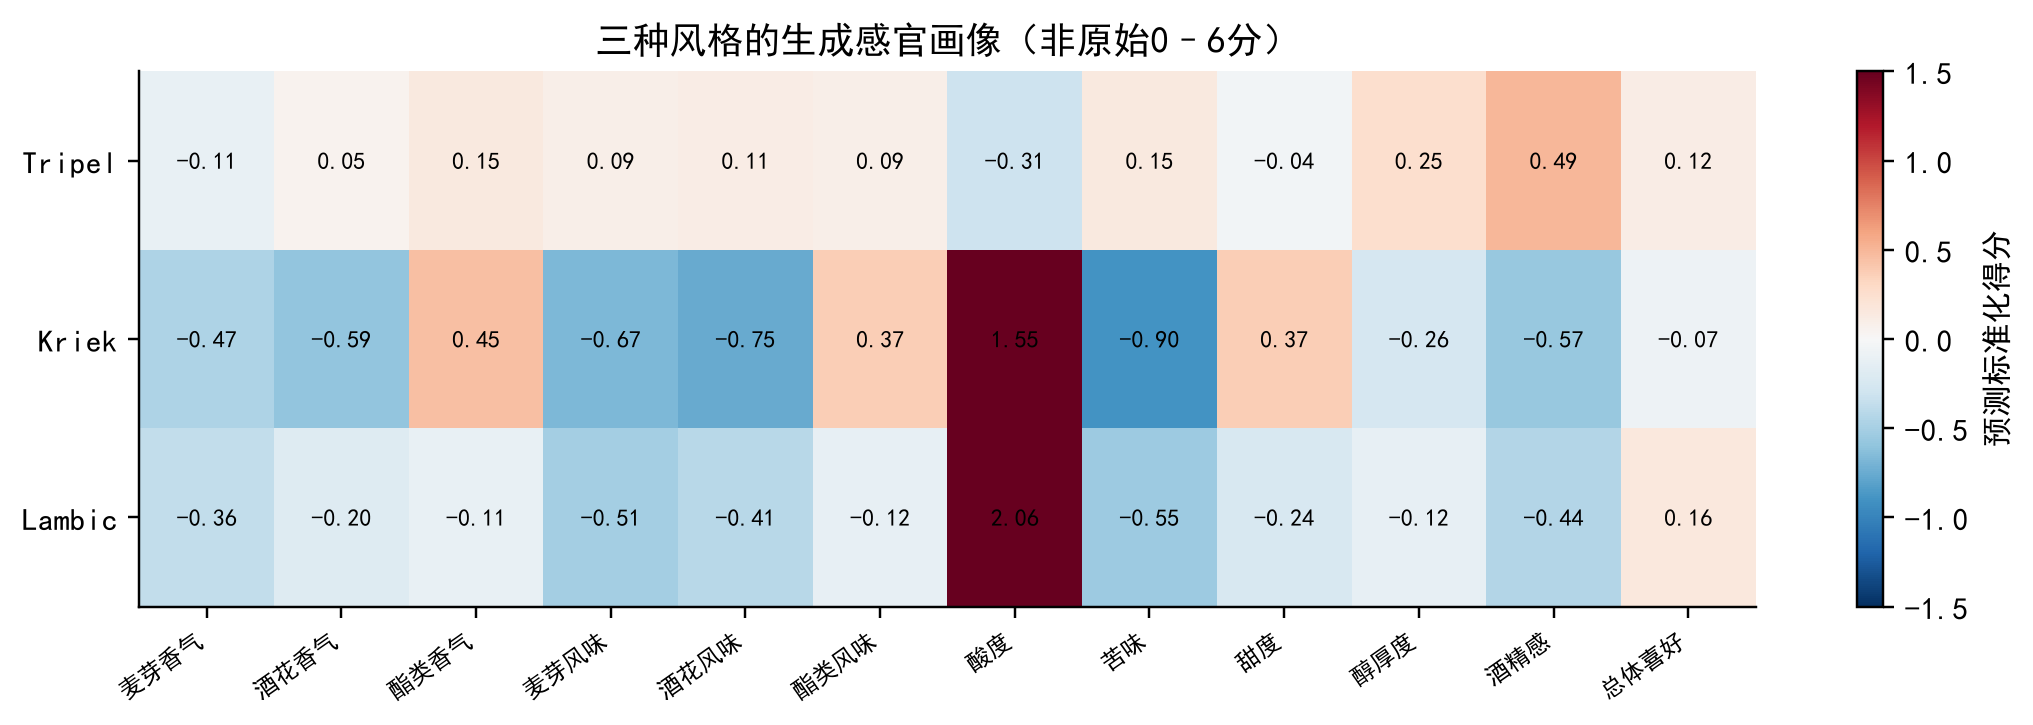

In [4]:
display(Image(filename=str(OUT/'figures/04_conditional_generation.png'))); display(Image(filename=str(OUT/'figures/05_style_profiles.png')))

## 复现

完整流程：python scripts/run_review.py。这里仅读取结果；需要13项受校验输入，其中两项是冻结历史策略/比较文件，详见REPRODUCIBILITY.md。

In [5]:
display(pd.read_csv(OUT/'q3_style_diversity_coverage.csv')); display(pd.read_csv(OUT/'q3_summary_consistency_audit.csv')); display(pd.read_csv(OUT/'q3_defect_evidence_summary.csv')); import json; print(json.loads((OUT/'q3_stale_guard_assessment.json').read_text(encoding='utf-8')))

,style,mode,n_train,n_test,marginal_wasserstein,mean_shift_RMS,real_nearest_train,generated_nearest_train,duplicate_fraction,outside_training_range,generated_missing_rate,n_generated,...,holdout_total_scaled_variance,holdout_variance_status,generated_pairwise_RMS_mean,training_pairwise_RMS_mean,generated_to_same_style_train_mean,generated_to_same_style_train_q95,holdout_to_same_style_train_mean,training_leave_one_out_mean,train_nn_radius95,holdout_to_generated_mean,holdout_covered_at_train_nn95,generated_in_train_nn95_fraction
0,Amber,conditional_local,10,2,0.801909,1.132679,1.362666,0.177542,0.0,0.0,0.000779,100,...,465.142184,estimable_but_small_sample,0.876397,1.100258,0.177542,0.447410,1.520926,0.947880,1.021452,1.457948,0.000000,1.00
1,Amber,conditional_resample,10,2,0.813076,1.144398,1.362666,0.000000,1.0,0.0,0.000173,100,...,465.142184,estimable_but_small_sample,0.961875,1.100258,0.000000,0.000000,1.520926,0.947880,1.021452,1.520926,0.000000,1.00
2,Amber,unconditional_local,10,2,0.836219,1.090957,1.362666,0.190396,0.0,0.0,0.002424,100,...,465.142184,estimable_but_small_sample,1.231882,1.100258,0.963318,1.573545,1.520926,0.947880,1.021452,1.361510,0.500000,0.70
3,Blond,conditional_local,25,6,0.407673,0.460315,0.894489,0.197617,0.0,0.0,0.002165,100,...,296.409203,estimable_but_small_sample,1.098119,1.283828,0.197617,0.484818,0.979923,0.886795,1.502068,0.931083,0.833333,1.00
4,Blond,conditional_resample,25,6,0.412740,0.469711,0.894489,0.000000,1.0,0.0,0.001558,100,...,296.409203,estimable_but_small_sample,1.250111,1.283828,0.000000,0.000000,0.979923,0.886795,1.502068,0.979923,0.833333,1.00
5,Blond,unconditional_local,25,6,0.416147,0.474515,0.894489,0.194343,0.0,0.0,0.001861,100,...,296.409203,estimable_but_small_sample,1.100172,1.283828,0.743193,1.214531,0.979923,0.886795,1.502068,0.934220,0.833333,0.99
6,Brett/cofermented,conditional_local,5,1,0.815384,0.978186,0.781249,0.251783,0.0,0.0,0.000000,100,...,NaN,undefined_n_less_than_2,1.166631,1.545564,0.251783,0.600016,0.798320,1.163640,2.023243,0.693449,1.000000,1.00
7,Brett/cofermented,conditional_resample,5,1,0.764009,0.861587,0.781249,0.000000,1.0,0.0,0.000000,100,...,NaN,undefined_n_less_than_2,1.225887,1.545564,0.000000,0.000000,0.798320,1.163640,2.023243,0.798320,1.000000,1.00
8,Brett/cofermented,unconditional_local,5,1,0.702412,0.711680,0.781249,0.173222,0.0,0.0,0.002121,100,...,NaN,undefined_n_less_than_2,1.179327,1.545564,1.030227,1.386851,0.798320,1.163640,2.023243,0.726915,1.000000,0.99
9,Brown,conditional_local,10,2,0.553102,0.683906,0.835087,0.165872,0.0,0.0,0.000693,100,...,242.012720,estimable_but_small_sample,0.821479,1.042415,0.165872,0.427818,1.000828,0.906235,0.997944,0.949909,0.500000,1.00


,field,unit,formula_status,constituent_list_status,transform_evidence,n_generated,generated_missing,consistency_error,recomputed,status,reason
0,esters_sum,NaN,not_verified,not_verified,not_verified,2200,0,NaN,False,未验证,No complete evidenced formula + constituents +...
1,aroma_hops_sum,NaN,not_verified,not_verified,not_verified,2200,118,NaN,False,未验证,No complete evidenced formula + constituents +...
2,acids_sum,NaN,not_verified,not_verified,not_verified,2200,0,NaN,False,未验证,No complete evidenced formula + constituents +...
3,sulfur_sum,NaN,not_verified,not_verified,not_verified,2200,0,NaN,False,未验证,No complete evidenced formula + constituents +...
4,kcalperc,kcal%,not_verified,not_verified,empirical_pairing_log10; not proof of constitu...,2200,0,NaN,False,未验证,No complete evidenced formula + constituents +...


,field,n,native_known,native_missing,calibrated_missing,presence_mismatch,numeric_source_conflict,zero_semantics_unknown,threshold_unknown,interpretation
0,DMS,250,250,0,0,0,0,1,0,"counts are overlapping evidence flags, not mut..."
1,X2.3.butanedione,250,241,9,0,9,3,9,0,"counts are overlapping evidence flags, not mut..."
2,X4VG,250,250,0,0,0,0,168,0,"counts are overlapping evidence flags, not mut..."
3,X.E..2.nonenal,250,250,0,1,1,2,0,250,"counts are overlapping evidence flags, not mut..."


{'folds': 5, 'model_mean_MAE': 0.31267338574610315, 'baseline_mean_MAE': 0.3120132162285625, 'paired_mean_MAE_difference': 0.000660169517540643, 'model_better_folds': 2, 'mean_R2': -0.11719362217101, 'has_mean_MAE_advantage': False, 'selection_action': 'none; auxiliary configuration and Q1 frozen selection unchanged', 'allowed_claim': '模型代理约束满足', 'disallowed_claim': '实际陈旧酒花缺陷不恶化', 'evidence_limit': 'No predictive advantage shown over mean baseline in these fixed training folds; not an actual safety/quality measurement.'}


In [6]:
display(pd.read_csv(OUT/'q3_transfer_compound_summary.csv')); display(pd.read_csv(OUT/'q3_transfer_sensory_summary.csv')); display(pd.read_csv(OUT/'q3_transfer_summary.csv')[['source_beer','before_diagnostic_style','after_diagnostic_style']])

,field,chemical_name,before_median,after_median,paired_delta_median,known_pairs
0,DMS,Dimethyl sulfide,1.179344,1.179344,0.000000,11
1,ethyl_acetate,Ethyl acetate,1.025315,1.420526,0.446321,11
2,ethyl_hexanoate,Ethyl hexanoate,-0.909195,-0.502663,0.446668,11
3,isoamyl_alcohol,Isoamyl alcohol,1.424732,1.592908,0.196223,11
4,X4VG,4-vinylguaiacol,-2.013157,-2.013157,0.000000,11
5,acetic_acid.g.L.,Acetic acid,-1.045757,-0.901843,0.264137,11
6,lactic_acid.mg.L.,Lactic acid,1.877947,2.054480,0.144014,11
7,pH,pH,0.613486,0.609387,-0.006540,11
8,bitterness,Iso-alpha acids,1.348860,1.256102,-0.052081,11
9,ethanol..v.v.,Ethanol,0.715472,0.868726,0.151993,11


,target,before_mean,after_mean,paired_mean_delta
0,A_malt_all,-0.372787,-0.169754,0.203033
1,A_malt_grain,-0.055654,-0.009019,0.046636
2,A_malt_bread,-0.212159,-0.080739,0.131420
3,A_malt_cara,-0.313405,-0.086454,0.226951
4,A_malt_burn,-0.190192,-0.201477,-0.011286
5,A_hops_all,-0.504953,-0.122589,0.382363
6,A_hops_citrus,-0.190667,-0.086798,0.103869
7,A_hops_tropical,-0.197119,-0.141804,0.055316
8,A_hops_noble,-0.341058,-0.008170,0.332888
9,A_hops_woody,-0.112643,-0.131223,-0.018581


,source_beer,before_diagnostic_style,after_diagnostic_style
0,28,Saison,Tripel
1,81,Pils/Lager,Tripel
2,90,Pils/Lager,Blond
3,96,Pils/Lager,Blond
4,119,Pils/Lager,Blond
5,124,Pils/Lager,Blond
6,139,Pils/Lager,Blond
7,185,Pils/Lager,Blond
8,209,Pils/Lager,Blond
9,218,Pils/Lager,Tripel
